## Loading relevant packages

In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:

import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("AviationData.csv", encoding="cp1252")

# Standardize column names used in this analysis
df = df.rename(columns={
    "Aircraft.damage": "Aircraft.Damage",
    "Broad.phase.of.flight": "Broad.Phase.of.Flight"
})

# Keep accidents from 1983 to 2023
df["Event.Date"] = pd.to_datetime(df["Event.Date"], errors="coerce")
df = df[
    (df["Event.Date"] >= "1983-01-01") &
    (df["Event.Date"] <= "2023-12-31")
].copy()

print(df.shape)
df.head()


C:\Users\Admin\AppData\Local\Temp\ipykernel_14164\2660247039.py:4: DtypeWarning: Columns (6,7,28) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("AviationData.csv", encoding="cp1252")


(85289, 31)


,Event.Id,Investigation.Type,Accident.Number,Event.Date,Location,Country,Latitude,Longitude,Airport.Code,Airport.Name,...,Purpose.of.flight,Air.carrier,Total.Fatal.Injuries,Total.Serious.Injuries,Total.Minor.Injuries,Total.Uninjured,Weather.Condition,Broad.Phase.of.Flight,Report.Status,Publication.Date
3600,20001214X42040,Accident,LAX83LA093,1983-01-01,"ARROYO GRANDE, CA",United States,NaN,NaN,NaN,NaN,...,Personal,NaN,0.0,1.0,0.0,1.0,VMC,Landing,Probable Cause,NaN
3601,20001214X42095,Accident,SEA83LA036,1983-01-01,"NEWPORT, OR",United States,NaN,NaN,ONP,NEWPORT MUNICIPAL,...,Personal,NaN,0.0,0.0,1.0,3.0,VMC,Approach,Probable Cause,NaN
3602,20001214X42067,Accident,MKC83LA056,1983-01-01,"WOODBINE, IA",United States,NaN,NaN,3YR,MUNICIPAL,...,Personal,NaN,0.0,0.0,0.0,2.0,VMC,Landing,Probable Cause,NaN
3603,20001214X42063,Accident,MKC83LA050,1983-01-01,"MARYVILLE, MO",United States,NaN,NaN,78Y,RANKIN,...,Personal,NaN,0.0,0.0,0.0,1.0,VMC,Takeoff,Probable Cause,NaN
3604,20001214X42018,Accident,LAX83FUG11,1983-01-01,"UPLAND, CA",United States,NaN,NaN,CCB,CABLE,...,Personal,NaN,0.0,0.0,2.0,0.0,VMC,Approach,Probable Cause,NaN


## conduct EDA: visualization and statistical measures to understand the structure of the data

In [4]:

print("Rows and columns:", df.shape)

print("\nMissing values:")
print(df.isnull().sum().sort_values(ascending=False).head(10))

print("\nSummary statistics:")
print(df[[
    "Total.Fatal.Injuries",
    "Total.Serious.Injuries",
    "Total.Uninjured"
]].describe())


Rows and columns: (85289, 31)

Missing values:
Schedule                 73244
Air.carrier              68876
FAR.Description          56830
Aircraft.Category        56566
Longitude                50919
Latitude                 50910
Airport.Code             36854
Airport.Name             34775
Broad.Phase.of.Flight    27163
Publication.Date         13769
dtype: int64

Summary statistics:
       Total.Fatal.Injuries  Total.Serious.Injuries  Total.Uninjured
count          73913.000000            72808.000000     79386.000000
mean               0.657530                0.283595         5.461051
std                5.576903                1.574753        28.412117
min                0.000000                0.000000         0.000000
25%                0.000000                0.000000         0.000000
50%                0.000000                0.000000         1.000000
75%                0.000000                0.000000         2.000000
max              349.000000              161.000000      

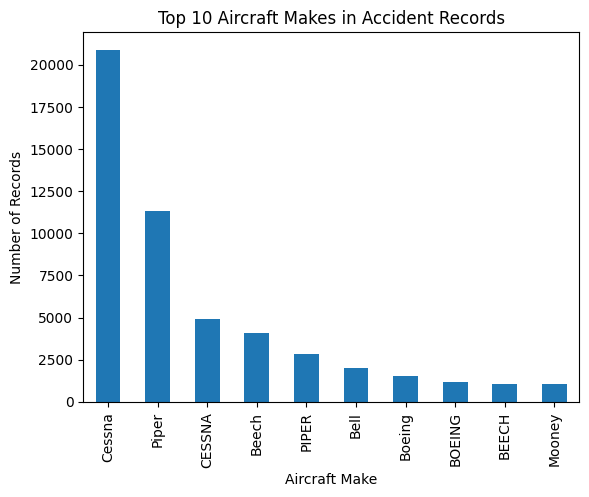

In [5]:

df["Make"].value_counts().head(10).plot(kind="bar")

plt.title("Top 10 Aircraft Makes in Accident Records")
plt.xlabel("Aircraft Make")
plt.ylabel("Number of Records")
plt.show()


In [11]:
print(df.columns.tolist())

['Event.Id', 'Investigation.Type', 'Accident.Number', 'Event.Date', 'Location', 'Country', 'Latitude', 'Longitude', 'Airport.Code', 'Airport.Name', 'Injury.Severity', 'Aircraft.Damage', 'Aircraft.Category', 'Registration.Number', 'Make', 'Model', 'Amateur.Built', 'Number.of.Engines', 'Engine.Type', 'FAR.Description', 'Purpose.of.flight', 'Air.carrier', 'Total.Fatal.Injuries', 'Total.Serious.Injuries', 'Total.Minor.Injuries', 'Total.Uninjured', 'Weather.Condition', 'Report.Status', 'Publication.Date', 'Fatal.Serious.Injuries', 'Total.Occupants', 'Fatal.Serious.Injury.Rate', 'Aircraft.Destroyed']


In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("cleaned_aviation_data.csv")


df = df.rename(columns={
    "Total.Occupants": "Total.Aboard",
    "Fatal.Serious.Injury.Rate": "Fatal.Serious.Frac",
    "Aircraft.Destroyed": "Destroyed",
})


print(df[["Destroyed", "Fatal.Serious.Frac", "Total.Aboard", "Make", "Model"]].isna().sum())
df = df.dropna(subset=["Destroyed", "Fatal.Serious.Frac", "Total.Aboard", "Make", "Model"]).copy()


df["Destroyed"] = df["Destroyed"].astype(int)

df["Make"] = df["Make"].str.strip().str.upper()
df["Model"] = df["Model"].astype(str).str.strip().str.upper()
df["Make.Model"] = df["Make"] + " " + df["Model"]


biggest = df.groupby("Make.Model")["Total.Aboard"].max()
df["Size"] = df["Make.Model"].map(biggest).apply(lambda x: "Large" if x > 20 else "Small")

small = df[df["Size"] == "Small"]
large = df[df["Size"] == "Large"]

print(len(df), len(small), len(large))

Destroyed             1324
Fatal.Serious.Frac    3885
Total.Aboard          3028
Make                     3
Model                   18
dtype: int64
16763 16253 510


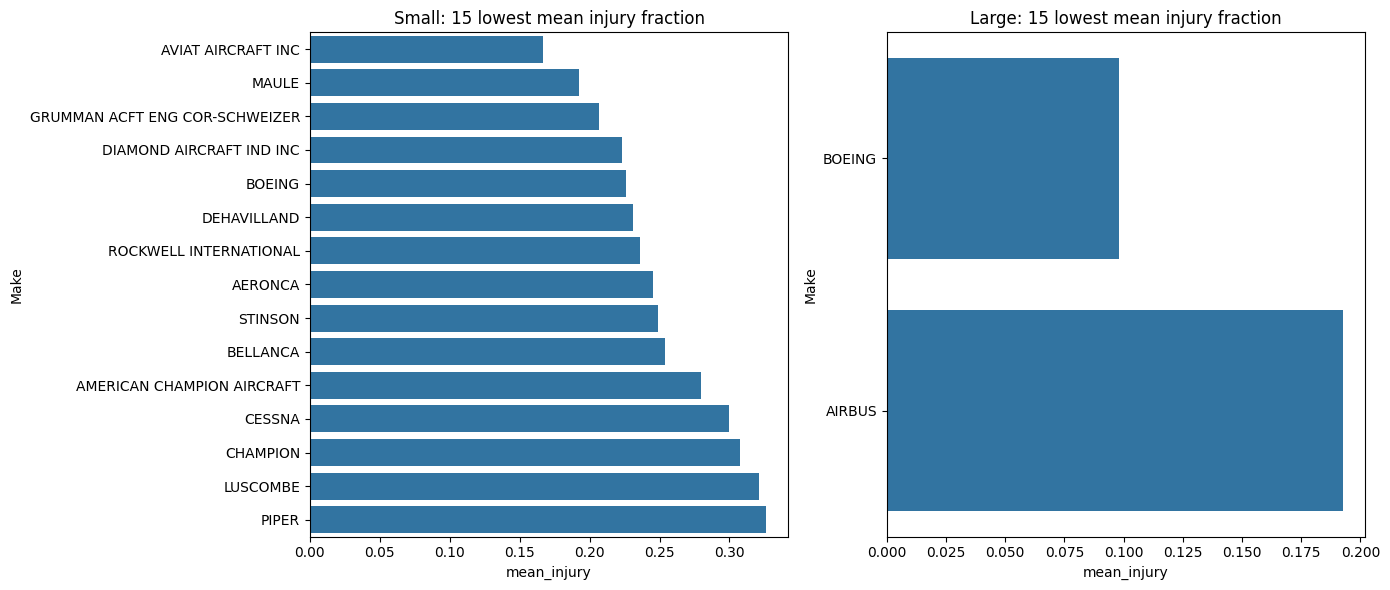

In [15]:
def by_group(data, col):
    t = data.groupby(col).agg(
        n=("Destroyed", "size"),
        mean_injury=("Fatal.Serious.Frac", "mean"),
        destroyed_rate=("Destroyed", "mean"))
    return t

small_make = by_group(small, "Make")
large_make = by_group(large, "Make")

# keep makes with enough accidents (lower to 30 if large has too few)
small_make = small_make[small_make["n"] >= 50]
large_make = large_make[large_make["n"] >= 50]

small15 = small_make.nsmallest(15, "mean_injury")
large15 = large_make.nsmallest(15, "mean_injury")

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sns.barplot(x=small15["mean_injury"], y=small15.index, ax=axes[0])
axes[0].set_title("Small: 15 lowest mean injury fraction")
sns.barplot(x=large15["mean_injury"], y=large15.index, ax=axes[1])
axes[1].set_title("Large: 15 lowest mean injury fraction")
plt.tight_layout()
plt.show()

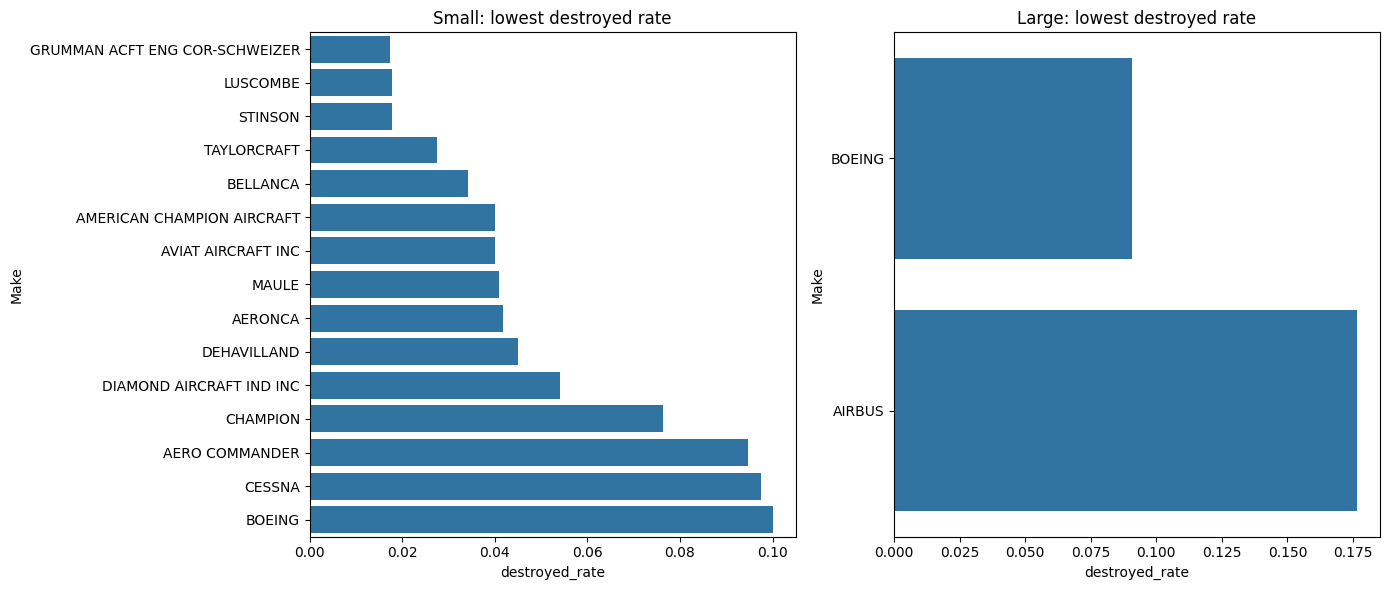

                                   n  mean_injury  destroyed_rate
Make                                                             
GRUMMAN ACFT ENG COR-SCHWEIZER    58     0.206897        0.017241
LUSCOMBE                         112     0.321429        0.017857
STINSON                          112     0.249256        0.017857
TAYLORCRAFT                       73     0.349315        0.027397
BELLANCA                         176     0.254261        0.034091
AMERICAN CHAMPION AIRCRAFT        50     0.280000        0.040000
AVIAT AIRCRAFT INC                75     0.166667        0.040000
MAULE                            171     0.192593        0.040936
AERONCA                          168     0.245040        0.041667
DEHAVILLAND                       89     0.230828        0.044944
DIAMOND AIRCRAFT IND INC          74     0.222973        0.054054
CHAMPION                         131     0.307888        0.076336
AERO COMMANDER                    74     0.398649        0.094595
CESSNA    

In [16]:
small_destroy = small_make.nsmallest(15, "destroyed_rate")
large_destroy = large_make.nsmallest(15, "destroyed_rate")

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sns.barplot(x=small_destroy["destroyed_rate"], y=small_destroy.index, ax=axes[0])
axes[0].set_title("Small: lowest destroyed rate")
sns.barplot(x=large_destroy["destroyed_rate"], y=large_destroy.index, ax=axes[1])
axes[1].set_title("Large: lowest destroyed rate")
plt.tight_layout()
plt.show()

print(small_destroy)
print(large_destroy)

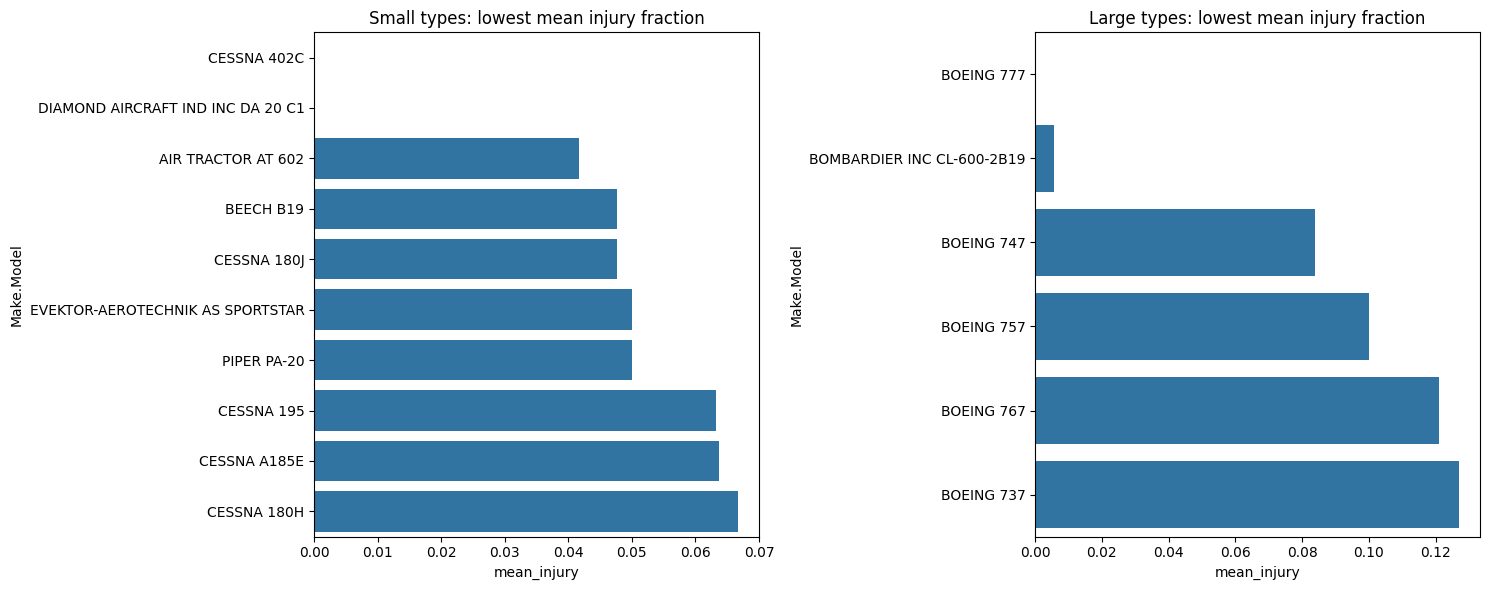

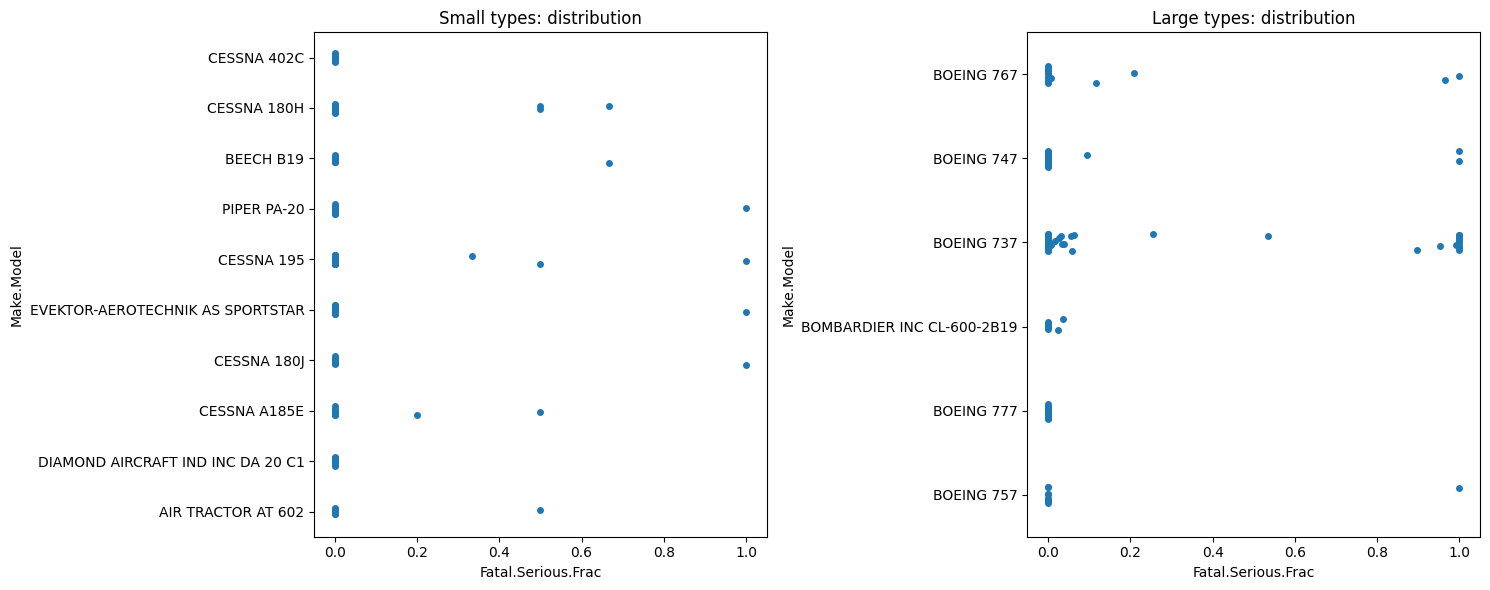

In [17]:
small_type = by_group(small, "Make.Model")
large_type = by_group(large, "Make.Model")

# at least 10 accidents per type
small_type = small_type[small_type["n"] >= 10]
large_type = large_type[large_type["n"] >= 10]

small_best = small_type.nsmallest(10, "mean_injury")
large_best = large_type.nsmallest(10, "mean_injury")

# Mean fraction, side by side
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.barplot(x=small_best["mean_injury"], y=small_best.index, ax=axes[0])
axes[0].set_title("Small types: lowest mean injury fraction")
sns.barplot(x=large_best["mean_injury"], y=large_best.index, ax=axes[1])
axes[1].set_title("Large types: lowest mean injury fraction")
plt.tight_layout()
plt.show()

# Distribution (strip plot)
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.stripplot(data=small[small["Make.Model"].isin(small_best.index)],
              x="Fatal.Serious.Frac", y="Make.Model", ax=axes[0])
axes[0].set_title("Small types: distribution")
sns.stripplot(data=large[large["Make.Model"].isin(large_best.index)],
              x="Fatal.Serious.Frac", y="Make.Model", ax=axes[1])
axes[1].set_title("Large types: distribution")
plt.tight_layout()
plt.show()

## Exploring Other Variables

In [19]:
def factor_summary(col, min_n=30):
    t = df.groupby(col).agg(
        n=("Destroyed", "size"),
        destroyed_rate=("Destroyed", "mean"),
        mean_injury=("Fatal.Serious.Frac", "mean"))
    t = t[t["n"] >= min_n]          # ignore tiny groups
    print(t.round(3))

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    sns.barplot(data=df[df[col].isin(t.index)], x=col, y="Destroyed", ax=axes[0])
    axes[0].set_title(f"Destroyed rate by {col}")
    sns.barplot(data=df[df[col].isin(t.index)], x=col, y="Fatal.Serious.Frac", ax=axes[1])
    axes[1].set_title(f"Mean injury fraction by {col}")
    plt.tight_layout()
    plt.show()

                       n  destroyed_rate  mean_injury
Weather.Condition                                    
IMC                  851           0.356        0.673
Unk                  150           0.387        0.642
VMC                13999           0.076        0.275


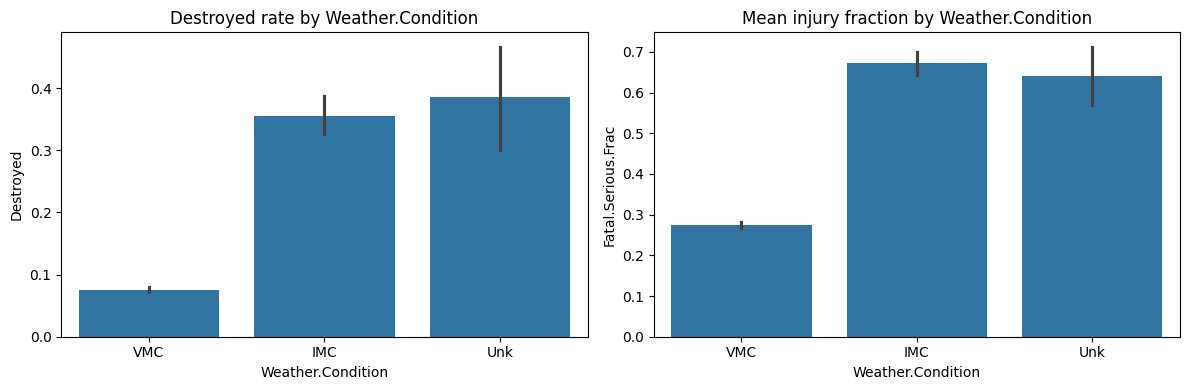

In [20]:
factor_summary("Weather.Condition")

                       n  destroyed_rate  mean_injury
Number.of.Engines                                    
1.0                13162           0.085        0.301
2.0                 2078           0.173        0.329
4.0                   42           0.143        0.211


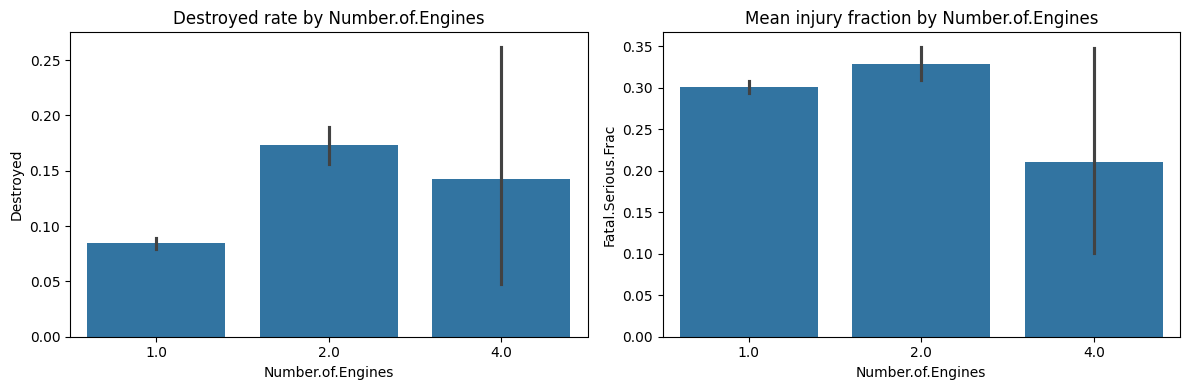

In [21]:
factor_summary("Number.of.Engines")